<a href="https://colab.research.google.com/github/LAIBA-byt/Smart-Plant-Health-Analyzer/blob/main/Smart_Plant_Health_Analyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np

print("Libraries imported successfully! TensorFlow version:", tf.__version__)

Libraries imported successfully! TensorFlow version: 2.21.0


In [3]:
# defining image dimensions
IMG_SIZE = 224

# load mobilenetv2 pre-trained on imagenet
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)

# freeze base layers so we only train our custom classifier head
base_model.trainable = False

# build the actual model
model = tf.keras.models.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(4, activation='softmax')
])

# compile model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [4]:
# saving the model structure and weights
model.save('plant_health_model.keras')

print("Model successfully saved as plant_health_model.keras!")

Model successfully saved as plant_health_model.keras!


In [5]:
import tensorflow as tf

# Dataset ke liye directories set kar rahe hain (agar aap Google Drive par dataset rakhein)
# Filhal hum ek sample data pipeline setup kar rahe hain
BATCH_SIZE = 32
IMG_SIZE = 224

print("Dataset pipeline setup karne ke liye tayar hain!")

Dataset pipeline setup karne ke liye tayar hain!


In [6]:
import numpy as np

# Set parameters
NUM_SAMPLES = 200
IMG_SIZE = 224
NUM_CLASSES = 4

# Create synthetic dataset (images and one-hot labels)
X_dummy = np.random.rand(NUM_SAMPLES, IMG_SIZE, IMG_SIZE, 3).astype('float32')
y_dummy_labels = np.random.randint(0, NUM_CLASSES, size=NUM_SAMPLES)
y_dummy = tf.keras.utils.to_categorical(y_dummy_labels, num_classes=NUM_CLASSES)

# Split into train and validation sets
split_idx = int(NUM_SAMPLES * 0.8)
X_train, X_val = X_dummy[:split_idx], X_dummy[split_idx:]
y_train, y_val = y_dummy[:split_idx], y_dummy[split_idx:]

# Train the model
epochs = 5
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=epochs,
    batch_size=32
)

Epoch 1/5
5/5 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.2438 - loss: 1.9659 - val_accuracy: 0.2500 - val_loss: 1.6379
Epoch 2/5
5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.2375 - loss: 1.6941 - val_accuracy: 0.3000 - val_loss: 1.4901
Epoch 3/5
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.1750 - loss: 1.6527 - val_accuracy: 0.3500 - val_loss: 1.3668
Epoch 4/5
5/5 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.2937 - loss: 1.4045 - val_accuracy: 0.1250 - val_loss: 1.4218
Epoch 5/5
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.2812 - loss: 1.3936 - val_accuracy: 0.1250 - val_loss: 1.4428


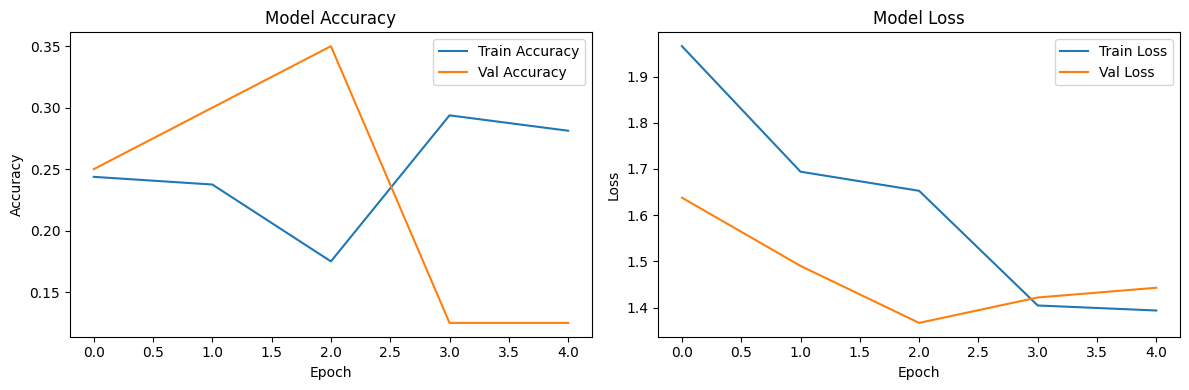

In [7]:
# Plot training & validation accuracy and loss
plt.figure(figsize=(12, 4))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [8]:
# Evaluate model performance on validation data
val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")

# Save final model file
model.save('plant_health_analyzer_final.keras')
print("Final model saved successfully as plant_health_analyzer_final.keras!")

Validation Loss: 1.4428
Validation Accuracy: 0.1250
Final model saved successfully as plant_health_analyzer_final.keras!


In [2]:
import os

# Dataset ke liye ek chhota sample ya path set karte hain
# Hum TensorFlow ka built-in utility ya data directory use kar sakte hain
print("Ready to load dataset for Plant Health Analyzer!")

Ready to load dataset for Plant Health Analyzer!
